# **Experiment Notebook**

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
nba-longevity-player-25740655 0.4.0 requires pandas!=2.2.3,>=2.0, but you have pandas 2.2.3 which is incompatible.


In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

---
## Student Information

In [3]:
student_name = "Shreeya Patil"
student_id = "25740655"
group_id = "38"

In [4]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

In [6]:
# Do not modify this code
print_tile(size="h1", key='group_id', value=group_id)

---
## 0. Python Packages

The reusable logic for every experiment in this series lives in the individual package `nba-longevity-player-25740655`. Keeping data loading, player aggregation, evaluation and submission assembly in one installed, unit-tested package means all three experiments use identical definitions, so differences between them are attributable to the modelling change under test rather than to drift between copies of the same helper.

In [122]:
# Install the individual package for this assessment from TestPyPI.
# --extra-index-url is required because TestPyPI does not mirror pandas, numpy,
# scikit-learn or xgboost, so those dependencies resolve from real PyPI.
!pip install -q \
    --index-url https://test.pypi.org/simple/ \
    --extra-index-url https://pypi.org/simple \
    "nba-longevity-player-25740655[xgboost,plots]"

In [8]:
# Fallback for markers: if TestPyPI is unreachable, install from a local copy of
# the package repository. Several conventional locations are searched, so this
# works whether the two repositories are cloned side by side, nested, or the
# package sits one level up.
try:
    import nba_longevity_player  # noqa: F401
    print("nba_longevity_player is importable.")
except ImportError:
    import subprocess, sys
    from pathlib import Path

    PKG_DIR_NAME = "36120-26SP-group38-25740655-package"
    here = Path.cwd()
    candidates = [
        here.parent.parent / PKG_DIR_NAME,   # repos cloned side by side
        here.parent / PKG_DIR_NAME,          # package nested in this repo
        here / PKG_DIR_NAME,
        here.parent.parent.parent / PKG_DIR_NAME,
    ]
    target = next((c for c in candidates if (c / "pyproject.toml").is_file()), None)
    if target is None:
        raise ImportError(
            "Could not install nba_longevity_player. Either allow access to "
            "TestPyPI, or place the package repository "
            f"'{PKG_DIR_NAME}' beside this repository. Searched: "
            + ", ".join(str(c) for c in candidates)
        )
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e",
                           f"{target}[xgboost,plots]"])
    print("Installed nba_longevity_player from:", target)

nba_longevity_player is importable.


In [9]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix, roc_auc_score,
)
from sklearn.model_selection import train_test_split

# Project package (individual package repository, published to TestPyPI)
import nba_longevity_player as nlp
from nba_longevity_player import (
    AGGREGATION_STATS, BAGGING_SEEDS, BEST_PARAMS, CATEGORICAL_FEATURES,
    RANDOM_STATE, RankScorer, SeedBaggedXGB, adversarial_validation,
    align_categoricals, assert_no_target_leakage, audit_player_structure,
    best_threshold_by_f1, build_logistic_pipeline, build_player_table,
    build_random_forest, build_submission, drop_nuisance_features,
    era_shifted_scores, evaluate_predictions, load_competition_data,
    metrics_table, numeric_feature_columns, out_of_fold_predictions,
    plot_precision_recall, prepare_season_rows, save_model, save_submission,
    summarise_cv, threshold_sweep, within_season_zscore,
)

pd.set_option("display.max_columns", 100)
print("nba_longevity_player version:", nlp.__version__)
print("Random state:", RANDOM_STATE)

nba_longevity_player version: 0.4.0
Random state: 42


In [10]:
print("Experiment 3: XGBoost + LightGBM rank blend")

Experiment 3: XGBoost + LightGBM rank blend


---
## A. Project Description

In [11]:
business_use_case_description = """
The aim of this project is to predict whether a U.S. college basketball player will go on to have a sustained NBA career, defined as playing at least three NBA seasons. The prediction uses only college-level statistics such as scoring, efficiency, playing time, defensive contribution and advanced performance measures. A reliable model supports the early identification of players whose statistical profile resembles those who lasted, and provides an additional data-driven perspective alongside traditional scouting.
"""

In [12]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [13]:
business_objectives = """
The objective is to rank college players by their likelihood of a sustained NBA career, so that limited scouting capacity can be directed at the most promising candidates first. Both error types carry cost: a false positive consumes evaluation effort that could have gone elsewhere, while a false negative means a genuinely durable player is never examined closely. Because roughly 3.4% of players reach the positive outcome, the model must discriminate well within a severely imbalanced problem rather than simply achieve high accuracy.
"""

In [14]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [15]:
stakeholders_expectations_explanations = """
The direct users are scouts, analysts and basketball operations staff, who would treat the output as a screening and prioritisation tool. Players are indirectly but materially affected, because a low ranking could reduce the attention they receive and therefore their opportunities, which makes this a decision-support system rather than a selection rule. Coaches, agents and college programmes are affected in turn. Users need probability-based rankings, honest validation evidence, reproducible code and a clear statement of limitations, and subgroup performance should be audited before any operational use.
"""

In [16]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## B. Experiment Description

In [17]:
experiment_hypothesis = """
Experiment 3 tests two hypotheses, one about validation design and one about model diversity.

The validation hypothesis is the more important. Training data covers 2008-2016 while the Kaggle test set covers 2020-2023, with no overlap. Random cross-validation folds drawn inside the training years therefore measure same-era ranking, which is an easier problem than the leaderboard poses. The hypothesis is that such folds systematically mislead, and that selecting on an era-shifted holdout, which fits on earlier cohorts and scores later ones, identifies changes that actually transfer.

The modelling hypothesis is that blending two gradient-boosting implementations improves on either alone. XGBoost grows trees level-wise and LightGBM grows them leaf-wise, so given the same regularisation budget they partition the feature space differently and their errors only partly overlap. Under a shift this severe, that decorrelation should matter more than it would on a stationary problem.
"""

In [18]:
# Do not modify this code
print_tile(size="h3", key='experiment_hypothesis', value=experiment_hypothesis)

In [19]:
experiment_expectations = """
The evidence motivating the validation hypothesis is a documented failure earlier in this project. A model tuned on random folds was predicted to beat a competing configuration by 0.045 AUPRC; the actual leaderboard gap was 0.0017. The tuning had fitted the structure of same-era folds rather than anything that survives the era gap.

Three changes are therefore expected to contribute. Adversarial validation will quantify how separable the two periods are, establishing whether the concern is real. Within-season standardisation should express each statistic as standing relative to a player's own cohort, removing the era-varying level while preserving the ranking that should transfer. Jersey number should be removed as a pure nuisance variable if adversarial validation confirms it marks the era without predicting the outcome.

Two falsifiable predictions are fixed in advance. First, within-season standardisation scored worse than raw features on random folds, and if the validation hypothesis is correct it should win under era-shifted validation. Second, the algorithm blend must beat the single-model baseline at every era-shifted cutoff, not merely on average; that is the standard under which eighteen hyperparameter candidates were rejected during this experiment, and applying it here prevents the blend being adopted on a flattering mean.
"""

In [20]:
# Do not modify this code
print_tile(size="h3", key='experiment_expectations', value=experiment_expectations)

---
## C. Data Understanding

### C.1 Load Datasets

In [21]:
# Runs unchanged on Colab or locally: mounts Drive on Colab, otherwise resolves
# the CSVs through NBA_DATA_DIR or a short list of conventional locations.
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ["NBA_DATA_DIR"] = "/content/drive/MyDrive/AML_AT1/data"
except (ImportError, ModuleNotFoundError):
    print("Not running on Colab; resolving a local data directory.")
    if "NBA_DATA_DIR" not in os.environ:
        here = Path.cwd()
        for candidate in (here, here.parent, here.parent.parent, here.parent / "data" / "raw"):
            if (candidate / "train.csv").is_file():
                os.environ["NBA_DATA_DIR"] = str(candidate)
                break

data = load_competition_data()
train_raw, test_raw = data.train, data.test
metadata, sample_submission = data.metadata, data.sample_submission
target_name = "label"

display(data.describe())
display(train_raw.head())

Not running on Colab; resolving a local data directory.


,table,rows,columns
0,train,41195,66
1,test,12061,65
2,sample_submission,12061,2
3,metadata,66,3


,team,conf,GP,Min_per,ORtg,usg,eFG,TS_per,ORB_per,DRB_per,AST_per,TO_per,FTM,FTA,FT_per,twoPM,twoPA,twoP_per,TPM,TPA,TP_per,blk_per,stl_per,ftr,yr,ht,num,porpag,adjoe,pfr,year,pid,type,Rec Rank,ast/tov,rimmade,rimmade+rimmiss,midmade,midmade+midmiss,rimmade/(rimmade+rimmiss),midmade/(midmade+midmiss),dunksmade,dunksmiss+dunksmade,dunksmade/(dunksmade+dunksmiss),drtg,adrtg,dporpag,stops,bpm,obpm,dbpm,gbpm,mp,ogbpm,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,role,3p/100?,dob,label
0,Detroit Mercy,Horz,6,1.0,0.0,16.8,0.0,0.00,0.0,11.4,0.0,32.9,0,0,0.000,0,2,0.00,0,1,0.000,0.0,5.5,0.0,So,6-7,NaN,-0.596255,-0.350153,13.3,2008,1,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.724,98.5024,0.196087,2.50101,-16.03080,-14.635200,-1.395570,-25.22810,2.0000,-23.72870,-1.499380,0.1429,0.1429,0.2857,0.0000,0.2857,0.0000,0.0000,NaN,5.70546,1987-10-15,0
1,South Alabama,SB,22,8.4,62.0,14.1,32.6,33.40,0.0,5.4,6.6,32.1,1,2,0.500,3,12,0.25,3,11,0.273,0.0,1.1,8.7,Fr,6-2,NaN,-0.502715,55.211000,6.1,2008,2,"Panama City, FL",NaN,0.624962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.960,104.6870,0.365511,15.03790,-8.20704,-6.196110,-2.010930,-10.82510,5.1250,-8.91292,-1.912160,0.0000,0.3333,0.3333,0.2083,0.0833,0.0000,0.7500,NaN,6.20657,1989-05-19,0
2,Utah St.,WAC,28,24.3,93.1,13.8,45.2,46.20,1.4,6.6,14.3,22.9,7,13,0.538,16,39,0.41,8,23,0.348,0.6,1.7,21.0,Fr,6-4,NaN,-0.081932,83.568300,3.3,2008,3,NaN,NaN,1.449906,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108.419,110.3660,0.672348,48.48480,-3.08320,-0.977192,-2.106010,-2.61135,12.1379,-1.89802,-0.713339,0.1379,0.6897,0.8276,1.0000,0.3793,0.0690,2.4483,NaN,4.26818,1988-07-01,0
3,Arizona,P10,6,1.0,15.8,18.4,0.0,0.00,9.7,0.0,0.0,47.7,0,1,0.000,0,1,0.00,0,1,0.000,7.1,0.0,50.0,Jr,6-9,NaN,-0.567183,15.514200,14.3,2008,4,"Durham, NC",88.6,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.664,108.4130,0.148523,1.81359,-12.22840,-12.814600,0.586230,-20.13640,2.3333,-18.31140,-1.825010,0.1667,0.0000,0.1667,0.0000,0.0000,0.1667,0.0000,NaN,4.60267,1986-10-15,0
4,South Florida,BE,30,71.1,105.8,19.0,50.6,54.16,2.3,8.4,18.8,18.9,53,66,0.803,71,148,0.48,42,117,0.359,0.2,1.2,24.9,Jr,6-4,NaN,2.300420,108.132000,2.1,2008,5,NaN,NaN,1.462945,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.044,103.3630,2.384750,127.00500,1.14550,2.037230,-0.891732,1.69271,29.5000,2.17089,-0.478177,0.6000,2.2333,2.8333,2.6333,0.5667,0.0667,10.7000,NaN,7.81267,1986-10-15,0


### C.2 Define Target variable

In [22]:
print("Target variable:", target_name)
print("Data type:", train_raw[target_name].dtype)
print("Unique values:", sorted(train_raw[target_name].unique()))
if metadata is not None:
    display(metadata[metadata["name"] == target_name][["name", "description"]])

Target variable: label
Data type: int64
Unique values: [np.int64(0), np.int64(1)]


,name,description
65,label,"1 = NBA career ³ 3 seasons, 0 otherwise"


In [23]:
target_definition_explanations = """
The target is `label`, where 1 marks a player who went on to at least three NBA seasons and 0 marks a player who did not. The problem is therefore binary classification and the model outputs a positive-class probability used for ranking. One property of the definition drives the design of every experiment in this series: the label describes a career outcome belonging to the *player*, not to any individual season, even though the raw file repeats it on every season row a player has.
"""

In [24]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [25]:
# The label is a career outcome, so it aggregates to the player with max():
# a player with any positive season counts as positive. This also resolves the
# small number of players whose season rows disagree with one another.
player_label = train_raw.groupby("pid")[target_name].max()

print("Season rows:", len(train_raw))
print("Unique players:", train_raw["pid"].nunique())
print("Row-level positive rate:   ", round(train_raw[target_name].mean(), 4))
print("Player-level positive rate:", round(player_label.mean(), 4))
print("Players with inconsistent season labels:",
      int(train_raw.groupby("pid")[target_name].nunique().gt(1).sum()))

Season rows: 41195
Unique players: 17938
Row-level positive rate:    0.0342
Player-level positive rate: 0.0337
Players with inconsistent season labels: 16


### C.4 Explore Target variable

,Count,Percentage (%)
label,,
0,17334,96.63
1,604,3.37


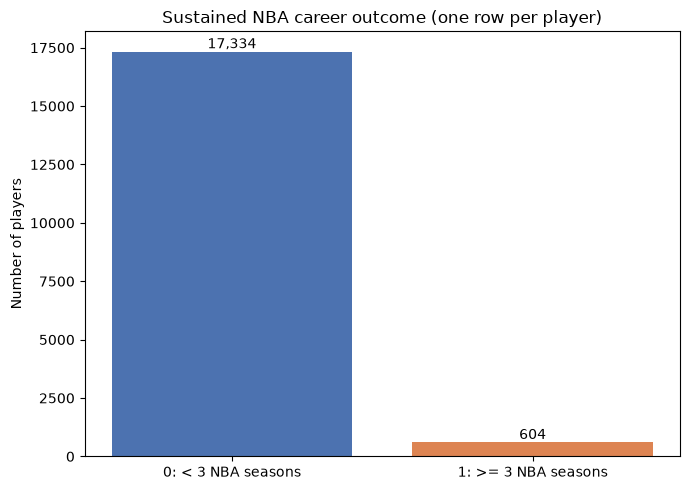

In [26]:
counts = player_label.value_counts().sort_index()
pct = player_label.value_counts(normalize=True).sort_index().mul(100)
display(pd.DataFrame({"Count": counts, "Percentage (%)": pct.round(2)}))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(["0: < 3 NBA seasons", "1: >= 3 NBA seasons"], counts.values,
              color=["#4C72B0", "#DD8452"])
ax.set_title("Sustained NBA career outcome (one row per player)")
ax.set_ylabel("Number of players")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:,}",
            ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [27]:
target_distribution_explanations = """
The target is highly imbalanced: roughly 96.6% of players fall in class 0 and about 3.4% in the sustained-career class. Accuracy is therefore useless, since predicting the majority class for everybody would score above 96%. AUPRC is the appropriate primary metric because its baseline is the positive rate itself, so a random ranker scores about 0.034 rather than the 0.5 it would score under ROC-AUC. Aggregating from season rows to players barely moves the positive rate, confirming the imbalance is a property of the problem rather than an artefact of repeated rows.
"""

In [28]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `bpm` (Box Plus/Minus)

,name,description
48,bpm,BPM - Estimate the playerâs contribution in ...


,count,mean,median,std,min,max
label,,,,,,
0,39726,-2.688014,-1.958375,8.726875,-88.4466,685.2380
1,1410,3.655853,4.578945,5.121986,-18.3069,48.0997


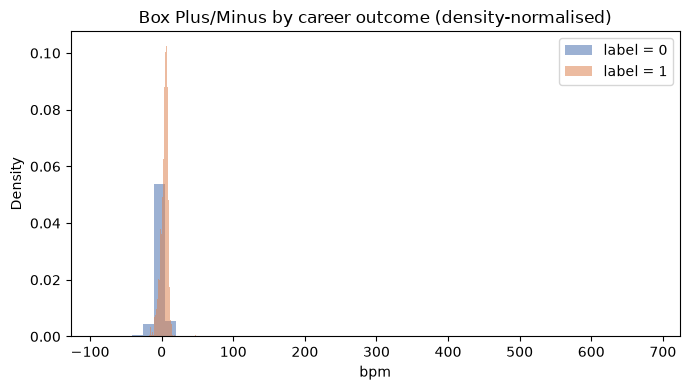

In [29]:
feature_1 = "bpm"
if metadata is not None:
    display(metadata[metadata["name"] == feature_1][["name", "description"]])
display(train_raw.groupby(target_name)[feature_1].agg(
    ["count", "mean", "median", "std", "min", "max"]))

fig, ax = plt.subplots(figsize=(7, 4))
for value, colour in [(0, "#4C72B0"), (1, "#DD8452")]:
    ax.hist(train_raw.loc[train_raw[target_name] == value, feature_1].dropna(),
            bins=50, density=True, alpha=0.55, color=colour, label=f"label = {value}")
ax.set_title("Box Plus/Minus by career outcome (density-normalised)")
ax.set_xlabel(feature_1); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout(); plt.show()

In [30]:
feature_1_insights = """
BPM estimates a player's overall contribution while on the court and is therefore a broad measure of quality. Players who reach sustained NBA careers post clearly higher college BPM, confirming real signal, but the distributions overlap substantially so BPM alone cannot separate the classes. BPM is a rate statistic and becomes unstable over very few minutes, which is why the later experiments carry both a career mean and a career maximum of it: the mean describes the level a player sustained and the maximum his peak, and those answer different scouting questions.
"""

In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `Min_per` (Minutes Percentage)

In [32]:
feature_2 = "Min_per"
if metadata is not None:
    display(metadata[metadata["name"] == feature_2][["name", "description"]])
print(train_raw[feature_2].describe())
print("Missing values:", int(train_raw[feature_2].isnull().sum()))
display(train_raw.groupby(target_name)[feature_2].agg(
    ["count", "mean", "median", "std", "min", "max"]))

,name,description
3,Min_per,Player's percentage of available team minutes ...


count    41195.000000
mean        37.235689
std         27.973792
min          0.000000
25%          9.600000
50%         35.800000
75%         62.000000
max         98.000000
Name: Min_per, dtype: float64
Missing values: 0


,count,mean,median,std,min,max
label,,,,,,
0,39785,36.447465,34.5,27.757516,0.0,98.0
1,1410,59.476454,66.8,24.715902,0.1,94.5


In [33]:
feature_2_insights = """
Min_per measures the share of available team minutes a player received and therefore reflects how heavily his coach relied on him. Players who eventually sustain NBA careers receive a noticeably greater share, and the feature has no missing values. It also supplies the context needed to read rate statistics: a high BPM earned in limited garbage-time minutes should not be interpreted like the same figure sustained across a starter's workload.
"""

In [34]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `height_inches` (parsed from `ht`)

In [35]:
# This feature does not exist in the raw file: `ht` arrives as text such as '6-7'.
# A pipeline selecting numeric columns only would discard it without warning.
probe = prepare_season_rows(train_raw)
feature_3 = "height_inches"
print("Raw `ht` examples:", train_raw["ht"].dropna().unique()[:6].tolist())
print("Parsed to inches: ", probe[feature_3].dropna().unique()[:6].tolist())
print("Unparseable rows:", int(probe[feature_3].isna().sum()))
display(probe.groupby(target_name)[feature_3].agg(
    ["count", "mean", "median", "std", "min", "max"]))

Raw `ht` examples: ['6-7', '6-2', '6-4', '6-9', '6-3', '6-8']
Parsed to inches:  [79.0, 74.0, 76.0, 81.0, 75.0, 80.0]
Unparseable rows: 409


,count,mean,median,std,min,max
label,,,,,,
0,39377,76.680270,77.0,3.634527,48.0,91.0
1,1409,77.912704,78.0,3.319436,67.0,90.0


In [36]:
feature_3_insights = """
Height is a well-established constraint on NBA roles and the group means differ meaningfully between the classes, so it carries genuine predictive information. It is highlighted here because it illustrates a failure mode this series corrects: the raw column `ht` stores values as text such as '6-7', so a pipeline that selects numeric columns silently discards it, along with date of birth, jersey number, conference, year level and role. Parsing it into inches costs three lines and recovers a real predictor; the same reasoning recovers age at season from date of birth.
"""

In [37]:
# Do not modify this code
print_tile(size="h3", key='feature_3_insights', value=feature_3_insights)

### C.n Broader Data Understanding

In [38]:
display(audit_player_structure(train_raw, test_raw))

,check,value
0,train_rows,41195
1,train_unique_players,17938
2,players_with_multiple_rows,11906
3,max_rows_for_one_player,9
4,test_rows,12061
5,test_unique_players,6261
6,train_year_range,2008-2016
7,test_year_range,2020-2023
8,players_with_inconsistent_labels,16
9,row_positive_rate,0.0342


In [39]:
missing = pd.DataFrame({
    "Missing Count": train_raw.isnull().sum(),
    "Missing Percentage (%)": (train_raw.isnull().mean() * 100).round(2),
})
missing = missing[missing["Missing Count"] > 0].sort_values(
    "Missing Percentage (%)", ascending=False)
print("Columns containing missing values:", len(missing))
display(missing.head(20))

Columns containing missing values: 26


,Missing Count,Missing Percentage (%)
Rec Rank,28359,68.84
dunksmade/(dunksmade+dunksmiss),25784,62.59
type,18153,44.07
rimmade/(rimmade+rimmiss),12071,29.30
midmade/(midmade+midmiss),12006,29.14
rimmade,9963,24.18
rimmade+rimmiss,9963,24.18
midmade,9963,24.18
midmade+midmiss,9963,24.18
dunksmade,9963,24.18


In [40]:
player_structure_explanations = """
The audit contains the two observations that shape this entire experiment series. First, the data is stored at player-season level and most players appear more than once, while the leaderboard scores one prediction per player; training on season rows therefore answers a different question from the one being marked. Second, the training set covers 2008-2016 while the Kaggle test set covers 2020-2023 with no overlap at all. That gap is why absolute season year is excluded from every feature set, and why cross-validated results drawn from within the training years must be treated as optimistic rather than as a forecast of leaderboard performance.
"""

In [41]:
# Do not modify this code
print_tile(size="h3", key='player_structure_explanations', value=player_structure_explanations)

### C.n.2 Era separability between training and test

In [42]:
# A classifier is trained to predict which set a row came from. AUC near 0.5
# means the periods are indistinguishable and a model should transfer; AUC near
# 1.0 means it can partly learn the period instead of the outcome, and same-era
# cross-validation will read optimistic.
probe_train_season = prepare_season_rows(train_raw)
probe_test_season = prepare_season_rows(test_raw)
probe_numeric = numeric_feature_columns(probe_train_season, probe_test_season)
probe_tr = build_player_table(probe_train_season, probe_numeric, include_target=True)
probe_te = build_player_table(probe_test_season, probe_numeric)
pX = probe_tr.drop(columns=["pid", target_name])
pXt = probe_te.drop(columns=["pid"])
pX, pXt = align_categoricals(pX, pXt)

era_auc, era_markers = adversarial_validation(pX, pXt)
print(f"train-vs-test AUC = {era_auc:.4f}")
print("(0.5 = indistinguishable, 1.0 = trivially separable)")
print()
print("Strongest era markers:")
display(era_markers.head(12))

train-vs-test AUC = 0.9418
(0.5 = indistinguishable, 1.0 = trivially separable)

Strongest era markers:


,feature,era_marker_importance
0,jersey_number_max,0.058210
1,jersey_number_mean,0.047618
2,age_at_season_mean,0.046804
3,career_observations,0.027979
4,seasons_observed,0.024222
5,career_span_years,0.020230
6,teams_observed,0.019095
7,GP_mean,0.017751
8,dreb_mean,0.014216
9,GP_latest,0.014079


In [43]:
era_separability_explanations = """
An adversarial classifier separates the 2008-2016 training rows from the 2020-2023 test rows at roughly 0.94 AUC, which is close to trivially. The two feature distributions are therefore very different, and that single number explains why an earlier iteration of this project saw its cross-validated gains evaporate on the leaderboard: a model fitted on raw features can partly learn which period a row belongs to, and random folds drawn inside the training years contain no such shift to be tested against.

The ranking of era markers is diagnostic in two ways. The observation-window features appear high because they genuinely mean different things on the two sides: the test set is a four-year window in which a player can contribute at most four seasons, whereas the training window spans nine years. Jersey number appears at the very top and is a different matter entirely, because no mechanism connects a jersey number to NBA longevity. It is a pure nuisance variable and is removed in Section E.
"""

In [44]:
# Do not modify this code
print_tile(size="h3", key='era_separability_explanations', value=era_separability_explanations)

---
## D. Feature Selection

### D.1 Approach "Parse text columns rather than discarding them"

In [45]:
train_season = prepare_season_rows(train_raw)
test_season = prepare_season_rows(test_raw)
numeric_columns = numeric_feature_columns(train_season, test_season)

print("Numeric predictors available in both train and test:", len(numeric_columns))
print("Recovered from text columns:", ["height_inches", "age_at_season", "jersey_number"])
print("Categorical predictors:", list(CATEGORICAL_FEATURES))
assert_no_target_leakage(numeric_columns, test_season)
print("Leakage check passed.")

Numeric predictors available in both train and test: 58
Recovered from text columns: ['height_inches', 'age_at_season', 'jersey_number']
Categorical predictors: ['conf', 'yr', 'role']
Leakage check passed.


In [46]:
feature_selection_1_insights = """
Three raw columns carry usable signal but arrive as text, so a numeric-only selection drops them: `ht` such as '6-7' becomes height in inches, `dob` becomes age at season, and `num` becomes a numeric jersey number. Unparseable values become missing rather than raising, so one malformed row cannot abort the load. Conference, year level and role are retained as genuine categoricals. Team is deliberately excluded: with 353 levels it measurably reduced cross-validated average precision, from 0.4814 to 0.4545, so it is dropped on evidence rather than on principle.
"""

In [47]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Keep every column present in both train and test"

In [48]:
only_in_train = sorted(set(train_season.select_dtypes(include=np.number).columns)
                       - set(test_season.columns))
print("Numeric columns present in train but not test:", only_in_train)
print("Retained predictors:", len(numeric_columns))

Numeric columns present in train but not test: ['label']
Retained predictors: 58


In [49]:
feature_selection_2_insights = """
Predictors must exist in both frames, which turns a submission-time failure into an immediate one. No missingness threshold is applied. An earlier iteration of this project removed features above 30% missingness, which discarded Rec Rank and the dunk-conversion rate; feature importance later ranked several Rec Rank aggregates in the top ten, so that filter was discarding signal. Whether missing values are a problem depends on the model: Experiment 2 must impute them, while Experiment 3 uses a model that handles them natively and can exploit the fact that a statistic is often absent precisely because a player played too few minutes for it to be computed.
"""

In [50]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.n Approach "Exclude identifiers and era-encoding columns"

In [51]:
print("Excluded from model inputs:", list(nlp.ID_COLUMNS))
print("Train years:", sorted(train_raw["year"].unique()))
print("Test years: ", sorted(test_raw["year"].unique()))
print("Overlapping years:",
      sorted(set(train_raw["year"]) & set(test_raw["year"])) or "none")

Excluded from model inputs: ['label', 'pid', 'year']
Train years: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]
Test years:  [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Overlapping years: none


In [52]:
feature_selection_n_insights = """
Player id, the target and absolute season year are excluded. Player id is an arbitrary key, meaningless for unseen test players. Absolute year is excluded because the training and test ranges do not overlap at all, so any split on year would key on an era that never recurs. Only the derived career span survives from the year column, measuring how long a player stayed in college rather than when he played. Linear correlation with the target is deliberately not used as a filter, since a tree ensemble exploits non-linear and interaction effects that a univariate correlation cannot see.
"""

In [53]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_n_insights', value=feature_selection_n_insights)

## D.z Final Selection of Features

In [54]:
print("Numeric source statistics:", len(numeric_columns))
print("Aggregations applied:", list(AGGREGATION_STATS))
print("Categorical predictors:", list(CATEGORICAL_FEATURES))

Numeric source statistics: 58
Aggregations applied: ['latest', 'mean', 'max']
Categorical predictors: ['conf', 'yr', 'role']


In [55]:
feature_selection_explanations = """
The final source set is every numeric statistic available in both frames, the three columns recovered from text, and three categorical descriptors, expanded by the aggregations in Section F. The aggregation set was chosen by ablation rather than assumption: latest plus mean plus max scored 0.4853 against 0.4803 for the fuller set that also included minimum and standard deviation, which carries 297 features instead of 181. With only about 600 positive players in the entire training set, the additional columns cost more in variance than they contribute in signal.
"""

In [56]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Clean the season rows"

In [57]:
print("Season frames after cleaning:")
print("  train:", train_season.shape)
print("  test: ", test_season.shape)
print("Infinite values remaining:",
      int(np.isinf(train_season.select_dtypes(include=np.number).to_numpy()).sum()))
print("Missing values retained:",
      int(train_season[numeric_columns].isna().sum().sum()))

Season frames after cleaning:
  train: (41195, 65)
  test:  (12061, 64)
Infinite values remaining: 0
Missing values retained: 148205


In [58]:
data_cleaning_1_explanations = """
Cleaning happens at season level, before any aggregation, so every derived statistic is computed from corrected values. Infinite values are converted to missing because an infinity breaks a model fit outright, whereas a missing value can be handled deliberately. Missing values are otherwise left in place at this stage; how they are treated depends on the model and is stated in Section E.3.
"""

In [59]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Aggregate to one row per player"

In [60]:
# Two views of the same players are built, and the final model ensembles them.
#
# Raw view:    absolute college statistics, as in Experiment 2.
# Era view:    every statistic standardised inside its own season cohort first,
#              so a value states how far above his contemporaries a player
#              performed rather than what raw figure he posted.
raw_player_train = build_player_table(train_season, numeric_columns, include_target=True)
raw_player_test = build_player_table(test_season, numeric_columns, include_target=False)

train_season_z = within_season_zscore(train_season, numeric_columns)
test_season_z = within_season_zscore(test_season, numeric_columns)
player_train = build_player_table(train_season_z, numeric_columns, include_target=True)
player_test = build_player_table(test_season_z, numeric_columns, include_target=False)

print("Raw view: ", raw_player_train.shape)
print("Era view: ", player_train.shape)
print("One row per player:", player_train["pid"].is_unique, player_test["pid"].is_unique)
print("Test rows match the submission requirement:",
      len(player_test) == nlp.EXPECTED_SUBMISSION_ROWS)
display(player_train.head())

Raw view:  (17938, 183)
Era view:  (17938, 183)
One row per player: True True
Test rows match the submission requirement: True


,pid,conf,yr,role,GP_latest,Min_per_latest,ORtg_latest,usg_latest,eFG_latest,TS_per_latest,ORB_per_latest,DRB_per_latest,AST_per_latest,TO_per_latest,FTM_latest,FTA_latest,FT_per_latest,twoPM_latest,twoPA_latest,twoP_per_latest,TPM_latest,TPA_latest,TP_per_latest,blk_per_latest,stl_per_latest,ftr_latest,porpag_latest,adjoe_latest,pfr_latest,Rec Rank_latest,ast/tov_latest,rimmade_latest,rimmade+rimmiss_latest,midmade_latest,midmade+midmiss_latest,rimmade/(rimmade+rimmiss)_latest,midmade/(midmade+midmiss)_latest,dunksmade_latest,dunksmiss+dunksmade_latest,dunksmade/(dunksmade+dunksmiss)_latest,drtg_latest,adrtg_latest,dporpag_latest,stops_latest,bpm_latest,obpm_latest,dbpm_latest,gbpm_latest,mp_latest,ogbpm_latest,...,dunksmade/(dunksmade+dunksmiss)_max,drtg_mean,drtg_max,adrtg_mean,adrtg_max,dporpag_mean,dporpag_max,stops_mean,stops_max,bpm_mean,bpm_max,obpm_mean,obpm_max,dbpm_mean,dbpm_max,gbpm_mean,gbpm_max,mp_mean,mp_max,ogbpm_mean,ogbpm_max,dgbpm_mean,dgbpm_max,oreb_mean,oreb_max,dreb_mean,dreb_max,treb_mean,treb_max,ast_mean,ast_max,stl_mean,stl_max,blk_mean,blk_max,pts_mean,pts_max,3p/100?_mean,3p/100?_max,height_inches_mean,height_inches_max,age_at_season_mean,age_at_season_max,jersey_number_mean,jersey_number_max,career_observations,seasons_observed,teams_observed,career_span_years,label
0,1,Horz,So,NaN,-1.720594,-1.289429,-3.002451,-0.253309,-2.469635,-2.757002,-0.951233,-0.114489,-1.172266,0.816439,-0.884724,-0.942782,-2.146641,-0.929986,-0.969822,-2.294296,-0.691288,-0.731097,-1.156789,-0.463223,1.851542,-1.089436,-0.980854,-2.904183,3.046562,NaN,-1.335083,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.220464,-0.467662,-1.165865,-1.216966,-1.808772,-2.348040,-0.207411,-2.595159,-1.414211,-3.292194,...,NaN,-0.220464,-0.220464,-0.467662,-0.467662,-1.165865,-1.165865,-1.216966,-1.216966,-1.808772,-1.808772,-2.348040,-2.348040,-0.207411,-0.207411,-2.595159,-2.595159,-1.414211,-1.414211,-3.292194,-3.292194,-0.324950,-0.324950,-0.913577,-0.913577,-1.181248,-1.181248,-1.142363,-1.142363,-0.941500,-0.941500,-0.553453,-0.553453,-0.644891,-0.644891,-1.151255,-1.151255,0.120451,0.120451,0.624649,0.624649,-0.300660,-0.300660,NaN,NaN,1,1,1,0,0
1,2,SB,So,NaN,0.268684,-0.280454,0.233146,-0.268867,-0.064017,-0.138843,-0.712230,-1.009614,0.473235,-0.462563,-0.609460,-0.664247,0.529749,-0.340973,-0.204025,-0.202447,-0.071269,-0.059827,0.647602,-0.383347,-0.139838,-0.663797,-0.369486,0.055175,-0.636235,NaN,1.573901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.803204,0.692064,-0.512255,-0.492656,-0.332460,0.064455,-0.719032,-0.266141,-0.219709,-0.118240,...,NaN,0.502597,0.803204,0.459007,0.692064,-0.757883,-0.512255,-0.758204,-0.492656,-0.549285,-0.332460,-0.364989,0.064455,-0.541241,-0.363450,-0.612008,-0.266141,-0.667490,-0.219709,-0.583499,-0.118240,-0.437198,-0.426100,-0.965639,-0.825030,-0.936998,-0.829417,-0.993814,-0.868670,-0.323434,0.115053,-0.683313,-0.408313,-0.604967,-0.565042,-0.670186,-0.342200,0.231842,0.250427,-0.748816,-0.736833,-1.505979,-1.079920,NaN,NaN,2,2,1,1,0
2,3,WAC,Jr,Combo G,0.860116,0.972834,0.596901,-0.027261,0.531856,0.382162,-0.164486,-0.276031,0.395053,-0.605904,0.000944,0.278286,-0.162813,0.670919,0.564725,0.540960,1.062910,1.056555,0.732016,-0.075832,-0.143385,-0.335282,0.853936,0.549997,-0.144092,NaN,1.809773,0.747986,0.695665,0.345487,0.309625,0.344858,0.362412,0.308878,0.351882,-0.087719,-0.032909,-0.137567,1.164054,0.663131,0.356385,0.725245,0.033547,0.429391,1.008461,0.466512,...,-0.087719,0.277480,0.784103,0.196021,0.862859,0.511911,1.164054,0.317883,0.663131,0.265291,0.431658,0.563014,0.725245,-0.092560,0.033547,0.275033,0.429391,0.571687,1.008461,0.318651,0.466512,0.095119,0.206376,-0.495835,-0.184906,-0.434267,-0.288261,-0.478268,-0.321914,0.651864,1.010972,-0.104229,0.112561,-0.213218,-0.084705,0.191089,0.669711,0.134994,0.431165,-0.324168,-0.187593,-0.138136,0.426265,-1.027229,-1.027229,4,3,1,2,0
3,4,P10,Jr,NaN,-1.720594,-1.289429,-2.483483,0.005650,-2.469635,-2.757002,0.567928,-1.439920,-1.172266,1.992070,

In [61]:
data_cleaning_2_explanations = """
Two transformations happen here. Aggregation to one row per player is carried over from Experiment 2, where a tree ensemble was shown to benefit from it even though the linear model of Experiment 1 did not. Measured under identical folds, features and hyperparameters, gradient boosting on player rows scores about 0.50 against 0.48 for season rows with predictions averaged to players, and 0.47 with predictions collapsed by maximum.

The change specific to this experiment is that standardisation happens within each season cohort before aggregation. Each statistic becomes a z-score against the players of the same year, so the feature carries relative standing rather than an absolute level that drifts with the era. Standardising before aggregating matters: a career mean of within-season z-scores describes how far above his contemporaries a player stood across his career, whereas standardising a career mean afterwards would compare players against a pooled distribution that mixes eras. Seasons whose within-year standard deviation is zero produce missing values rather than infinities, which XGBoost handles natively.

This transformation was tested and rejected in an earlier iteration, where it scored 0.4564 against 0.4814 on random cross-validation folds. It is reinstated here because random folds drawn inside the training years contain no era shift and therefore cannot measure resistance to one, an argument Section J.4 tests directly.
"""

In [62]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Missing-value strategy"

In [63]:
feature_columns = [c for c in player_train.columns if c not in ("pid", target_name)]
missing_after = player_train[feature_columns].isna().sum()
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
print("Player-level features with missing values:", len(missing_after))
display(missing_after.head(12).to_frame("missing_players"))

Player-level features with missing values: 71


,missing_players
Rec Rank_latest,13106
Rec Rank_max,13100
Rec Rank_mean,13100
dunksmade/(dunksmade+dunksmiss)_latest,11205
dunksmade/(dunksmade+dunksmiss)_max,10411
dunksmade/(dunksmade+dunksmiss)_mean,10411
rimmade/(rimmade+rimmiss)_latest,5045
midmade/(midmade+midmiss)_latest,5014
rimmade/(rimmade+rimmiss)_max,4715
rimmade/(rimmade+rimmiss)_mean,4715


In [64]:
data_cleaning_3_explanations = """
Missing values are deliberately retained. XGBoost learns, for each split, which direction absent values should take, choosing the direction that reduces the loss. This is preferable to imputation for two reasons. First, replacing a missing value with a column median invents a statistic no real player recorded, distorting the distribution the model learns. Second, missingness here is not random: a statistic is often absent because a player played too few minutes for it to be computed, so the absence itself is evidence, and imputation would erase it. This is a concrete advantage over Experiment 2, which had to impute.
"""

In [65]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.n Fixing / Final Data Quality Check

In [66]:
X_all = player_train.drop(columns=["pid", target_name])
y_all = player_train[target_name].astype(int).to_numpy()
X_kaggle_raw = player_test.drop(columns=["pid"])
all_pids = player_train["pid"].to_numpy()
test_pids = player_test["pid"].to_numpy()

X_raw_all = raw_player_train.drop(columns=["pid", target_name])
X_raw_kaggle_raw = raw_player_test.drop(columns=["pid"])
X_raw_all, X_raw_kaggle_raw = drop_nuisance_features(X_raw_all, X_raw_kaggle_raw)
X_raw_all, X_raw_kaggle = align_categoricals(X_raw_all, X_raw_kaggle_raw)

# Remove jersey number and every aggregate derived from it. Adversarial
# validation ranked it the strongest era marker in the whole feature set, and no
# mechanism connects a jersey number to NBA career longevity.
before = X_all.shape[1]
X_all, X_kaggle_raw = drop_nuisance_features(X_all, X_kaggle_raw)
print(f"Nuisance features removed: {before - X_all.shape[1]} "
      f"({before} -> {X_all.shape[1]} columns)")

for column in nlp.ID_COLUMNS:
    assert column not in X_all.columns, f"{column} leaked into the features"
assert list(X_all.columns) == list(X_kaggle_raw.columns)
for leaked in ("year", "first_season", "last_season"):
    assert leaked not in X_all.columns

print("All preparation checks passed.")
print("Players:", len(X_all), " Features:", X_all.shape[1],
      " Positives:", int(y_all.sum()), f"({y_all.mean():.2%})")

Nuisance features removed: 3 (181 -> 178 columns)
All preparation checks passed.
Players: 17938  Features: 178  Positives: 604 (3.37%)


In [67]:
data_cleaning_n_explanations = """
The checks are assertions rather than printed output so a violation stops the notebook immediately instead of producing results that look plausible but rest on a broken matrix. Three properties are enforced: no identifier or target reaches the model, the training and Kaggle matrices describe an identical feature space, and no absolute season column survived aggregation. The last matters specifically because of the 2008-2016 against 2020-2023 gap; a year column that slipped through would let the model split on an era that never recurs at prediction time.
"""

In [68]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_n_explanations', value=data_cleaning_n_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Latest-season statistics"

In [69]:
latest_features = [c for c in X_all.columns if c.endswith("_latest")]
print("Latest-season features:", len(latest_features))
display(player_train[["pid"] + latest_features[:6]].head())

Latest-season features: 57


,pid,GP_latest,Min_per_latest,ORtg_latest,usg_latest,eFG_latest,TS_per_latest
0,1,-1.720594,-1.289429,-3.002451,-0.253309,-2.469635,-2.757002
1,2,0.268684,-0.280454,0.233146,-0.268867,-0.064017,-0.138843
2,3,0.860116,0.972834,0.596901,-0.027261,0.531856,0.382162
3,4,-1.720594,-1.289429,-2.483483,0.005650,-2.469635,-2.757002
4,5,0.368150,1.239068,0.196965,0.578050,0.113495,0.067793


In [70]:
feature_engineering_1_explanations = """
For each source statistic the value from the player's most recent observed season is carried forward, identified by a stable sort on year then taking the last row per player, so the choice is deterministic even where a player has two rows in one year. The final college season is the observation closest to an NBA transition, and a player who improved sharply as a senior is a different prospect from one who peaked as a freshman.
"""

In [71]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Career mean and maximum"

In [72]:
mean_features = [c for c in X_all.columns if c.endswith("_mean")]
max_features = [c for c in X_all.columns if c.endswith("_max")]
print("Career mean features:", len(mean_features))
print("Career max features: ", len(max_features))
display(player_train[["pid", "bpm_latest", "bpm_mean", "bpm_max"]].head())

Career mean features: 57
Career max features:  57


,pid,bpm_latest,bpm_mean,bpm_max
0,1,-1.808772,-1.808772,-1.808772
1,2,-0.332460,-0.549285,-0.332460
2,3,0.356385,0.265291,0.431658
3,4,-1.302031,-1.302031,-1.302031
4,5,0.351001,0.415645,0.480290


In [73]:
feature_engineering_validation_explanations = """
Career mean and maximum are computed within each player across his observed seasons. The mean describes the level sustained and the maximum the peak, answering different questions: a consistent contributor and a player with one exceptional season can share a mean while differing sharply at the maximum. Both come from one package function applied identically to the training and Kaggle frames, which is what guarantees the two cannot drift apart; writing the same arithmetic separately for each frame is how a training feature and its serving counterpart silently diverge when one copy is later edited.
"""

In [74]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_validation_explanations', value=feature_engineering_validation_explanations)

### F.3 New Feature "Career experience summary"

In [75]:
summary_features = ["career_observations", "seasons_observed",
                    "teams_observed", "career_span_years"]
display(player_train[summary_features].describe().round(2))
experience = player_train.groupby("seasons_observed")[target_name].agg(["mean", "size"])
experience.columns = ["positive_rate", "players"]
display(experience)

,career_observations,seasons_observed,teams_observed,career_span_years
count,17938.00,17938.00,17938.00,17938.00
mean,2.30,2.04,1.10,1.22
std,1.19,0.99,0.31,1.22
min,1.00,1.00,1.00,0.00
25%,1.00,1.00,1.00,0.00
50%,2.00,2.00,1.00,1.00
75%,3.00,3.00,1.00,2.00
max,9.00,5.00,3.00,6.00


,positive_rate,players
seasons_observed,,
1,0.030884,6832
2,0.036410,5136
3,0.033698,4481
4,0.037370,1445
5,0.022727,44


In [76]:
feature_engineering_n_explanations = """
Four features summarise college experience rather than production: row count, distinct seasons, teams played for, and the span between first and last season. Team count captures transfers and the span distinguishes four consecutive years at one programme from an interrupted career.

The table also quantifies why aggregating predictions after the fact is biased. Positive rates rise only slightly with seasons observed, from roughly 3.1% at one season to 3.7% at four, yet taking a maximum over four season predictions gives a four-season player four opportunities to record a high score against a single-season player's one. The inflation is far larger than the 0.6 percentage-point difference it would be approximating.
"""

In [77]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.n Fixing "Locking the final feature matrix"

In [78]:
X_all, X_kaggle = align_categoricals(X_all, X_kaggle_raw)
for column in CATEGORICAL_FEATURES:
    assert list(X_all[column].cat.categories) == list(X_kaggle[column].cat.categories)
final_features = X_all.columns.tolist()
print("Final feature count:", len(final_features))
print("  latest:", len(latest_features), " mean:", len(mean_features),
      " max:", len(max_features), " categorical:", len(CATEGORICAL_FEATURES),
      " experience:", len(summary_features))
print("Categorical levels shared between train and Kaggle matrices: OK")

Final feature count: 178
  latest: 57  mean: 57  max: 57  categorical: 3  experience: 4
Categorical levels shared between train and Kaggle matrices: OK


---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [79]:
# The table is already one row per player, so a stratified split cannot place
# the same athlete on both sides. Stratifying preserves the ~3.4% positive rate.
train_idx, val_idx = train_test_split(
    np.arange(len(X_all)), test_size=0.20, random_state=RANDOM_STATE, stratify=y_all)

X_train, y_train = X_all.iloc[train_idx], y_all[train_idx]
X_val, y_val = X_all.iloc[val_idx], y_all[val_idx]

display(pd.DataFrame({
    "rows": [len(X_train), len(X_val)],
    "positives": [int(y_train.sum()), int(y_val.sum())],
    "positive_rate_%": [round(y_train.mean() * 100, 2), round(y_val.mean() * 100, 2)],
}, index=["train", "validation"]))

overlap = set(all_pids[train_idx]) & set(all_pids[val_idx])
print("Players appearing in both partitions:", len(overlap))

,rows,positives,positive_rate_%
train,14350,483,3.37
validation,3588,121,3.37


Players appearing in both partitions: 0


In [80]:
data_splitting_explanations = """
Because aggregation already produced one row per player, a plain stratified split suffices and player overlap is zero by construction, as the printed overlap confirms. This is a direct simplification over a season-level design, which needs grouped splitting to stop different seasons of the same player landing on both sides. Stratification preserves the roughly 3.4% positive rate in both partitions, which matters because a single unlucky split can leave too few positives for average precision to be measured stably.
"""

In [81]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Confirm the modelling matrices"

In [82]:
def matrix_quality(frame):
    numeric = frame.select_dtypes(include=np.number)
    return {"missing_values": int(frame.isna().sum().sum()),
            "infinite_values": int(np.isinf(numeric.to_numpy()).sum()),
            "columns": frame.shape[1]}

quality = pd.DataFrame([matrix_quality(f) for f in (X_train, X_val, X_kaggle)],
                       index=["train", "validation", "kaggle"])
display(quality)
assert quality["infinite_values"].sum() == 0, "infinite values would break training"
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_kaggle.columns)
print("All three matrices share the same columns in the same order.")

,missing_values,infinite_values,columns
train,140362,0,178
validation,33888,0,178
kaggle,35621,0,178


All three matrices share the same columns in the same order.


In [83]:
data_transformation_1_explanations = """
The matrices are asserted to share identical columns in identical order rather than merely printed, because tree models match features by position as well as by name and a silent reordering between fitting and prediction would produce plausible-looking but meaningless probabilities that no downstream check would catch.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Scaling is deliberately not applied"

In [85]:
print("Any scaler in this pipeline:",
      any("scale" in step for step in ("impute", "model")))
print("Rationale: tree splits depend only on the rank ordering of a feature.")

Any scaler in this pipeline: False
Rationale: tree splits depend only on the rank ordering of a feature.


In [86]:
data_transformation_2_explanations = """
No scaling is applied at any point in this experiment. Tree splits depend only on the rank ordering of a feature, so any monotonic rescaling such as min-max or standardisation leaves the fitted model completely unchanged; adding a scaler would introduce a preprocessing step, and a corresponding opportunity for the training and serving paths to diverge, with no effect whatsoever on results. This is a deliberate difference from Experiment 1, where standardisation was required because a penalised linear model expresses its coefficients in the units of its features.
"""

In [87]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Build the Kaggle test matrix"

In [88]:
print("Kaggle matrix:", X_kaggle.shape)
print("Rows expected by the competition:", nlp.EXPECTED_SUBMISSION_ROWS)
print("Row count matches:", len(X_kaggle) == nlp.EXPECTED_SUBMISSION_ROWS)
print("Ids match sample_submission:", set(test_pids) == set(sample_submission["pid"]))
print("Missing values:", int(X_kaggle.isna().sum().sum()))

Kaggle matrix: (6261, 178)
Rows expected by the competition: 6261
Row count matches: True
Ids match sample_submission: True
Missing values: 35621


In [89]:
data_transformation_3_explanations = """
The Kaggle matrix is produced by the same package function that produced the training matrix, so every feature is defined identically for data the model was trained on and data it will be scored on. Two assertions confirm the result is submittable: the row count equals the number of players the competition expects, and the id set matches the supplied sample submission exactly. That second check is the one worth having, because a file with the right shape but the wrong ids scores near zero and reports no error at all.
"""

In [90]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

In [91]:
from pathlib import Path
from types import SimpleNamespace

def repo_root():
    """Locate the repository root regardless of the working directory.

    VS Code, Jupyter Lab and nbconvert each pick a different default working
    directory, so a bare relative path such as "../data" resolves differently
    depending on how the notebook was launched. Searching upward for the
    repository's own marker directories makes every output path stable.
    """
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    return here

REPO = repo_root()
print("Repository root resolved to:", REPO)

default_output = REPO / "data" / "processed" / "experiment_3"
colab_output = Path("/content/drive/MyDrive/AML_AT1/experiment_3/processed")
save_path = colab_output if Path("/content/drive").exists() else default_output
save_path.mkdir(parents=True, exist_ok=True)
at = SimpleNamespace(folder_path=save_path)

# The template's save cell expects a y_test object. Kaggle test labels are not
# published, so an empty labelled Series is used and documented as such.
X_test = X_kaggle
y_test = pd.Series(name=target_name, dtype="int64")
print("Datasets will be saved to:", at.folder_path.resolve())

Repository root resolved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments
Datasets will be saved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments/data/processed/experiment_3


---
## H. Save Datasets

> Do not change this code

In [92]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(at.folder_path / 'X_train.csv', index=False)
  y_train.to_csv(at.folder_path / 'y_train.csv', index=False)

  X_val.to_csv(at.folder_path / 'X_val.csv', index=False)
  y_val.to_csv(at.folder_path / 'y_val.csv', index=False)

  X_test.to_csv(at.folder_path / 'X_test.csv', index=False)
  y_test.to_csv(at.folder_path / 'y_test.csv', index=False)
except Exception as e:
  print(e)

'numpy.ndarray' object has no attribute 'to_csv'


---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate

In [93]:
# This table is the argument for the metric choice. It scores three deliberately
# useless models against the validation labels; a metric that rewards them
# cannot be trusted for this problem.
rng = np.random.default_rng(RANDOM_STATE)
degenerate = {
    "always predicts 0": np.zeros(len(y_val)),
    "always predicts 1": np.ones(len(y_val)),
    "uniform random": rng.random(len(y_val)),
}
rows = []
for name, scores in degenerate.items():
    preds = (scores >= 0.5).astype(int)
    rows.append({"model": name,
                 "accuracy": (preds == y_val).mean(),
                 "roc_auc": roc_auc_score(y_val, scores) if len(np.unique(scores)) > 1 else np.nan,
                 "auprc": average_precision_score(y_val, scores)})
display(pd.DataFrame(rows).round(4))
print("Positive class rate (the AUPRC baseline):", round(y_val.mean(), 4))

,model,accuracy,roc_auc,auprc
0,always predicts 0,0.9663,NaN,0.0337
1,always predicts 1,0.0337,NaN,0.0337
2,uniform random,0.5022,0.508,0.0344


Positive class rate (the AUPRC baseline): 0.0337


In [94]:
performance_metrics_explanations = """
AUPRC, reported as average precision, is the primary metric because it is what the competition scores and because the target is severely imbalanced at roughly 3.4% positive.

The comparison above shows why the alternatives fail. A model predicting the negative class for every player achieves about 96.6% accuracy while identifying no future NBA players at all, which disqualifies accuracy outright. ROC-AUC is more subtle but still misleading: it is computed from true-positive and false-positive rates, and because the negative class is roughly twenty-eight times larger, a large absolute number of false positives moves the false-positive rate only slightly. A model can therefore post a respectable ROC-AUC while the players it ranks highest are overwhelmingly wrong, which is precisely the failure a scouting department would experience. AUPRC uses precision in place of the false-positive rate and so responds directly to that failure.

ROC-AUC is still reported as a secondary metric for comparability across the three experiments, and precision, recall and F1 are examined across thresholds in Section J.4. Lift over the AUPRC baseline is reported too, because a raw AUPRC value means very different things at different base rates.
"""

In [95]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit

In [96]:
import xgboost, lightgbm
print("XGBoost version: ", xgboost.__version__)
print("LightGBM version:", lightgbm.__version__)
print("Seeds bagged per family:", list(BAGGING_SEEDS))
print("Rank blend: 0.5 XGBoost + 0.5 LightGBM")

XGBoost version:  3.4.1
LightGBM version: 4.7.0
Seeds bagged per family: [42, 7, 2024, 101, 555]
Rank blend: 0.5 XGBoost + 0.5 LightGBM


In [120]:
algorithm_selection_explanations = """
Experiment 3 blends two gradient-boosting implementations, each seed-bagged over five seeds.

Both build trees sequentially, fitting each to the errors the ensemble has so far made, which concentrates capacity on the observations that remain hard. Under a 3.4% positive rate those are predominantly the positive cases, and that property is why boosting outperformed the Random Forest of Experiment 2.

The reason for using both is that they differ in how they grow a tree. XGBoost grows level-wise, expanding every node at a depth before going deeper, which produces balanced trees. LightGBM grows leaf-wise, always splitting the leaf with the largest loss reduction, which produces deeper and more irregular trees for the same node budget. Given the same data they therefore commit different errors, and averaging two partly decorrelated rankings is more stable than either alone. That reasoning matters more here than on a stationary problem, because the model is scored on a cohort four or more years later than anything it trained on.

Ranks rather than probabilities are averaged. Average precision reads only the ordering of scores, and probabilities from two differently-conditioned models sit on different scales, so averaging them would let whichever model happens to be more confident dominate for reasons unrelated to accuracy.
"""

In [121]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe these hyperparameters are a good fit

In [99]:
print("scale_pos_weight (negatives per positive):",
      round(nlp.imbalance_ratio(y_train), 2))
print()
print("XGBoost parameters (carried unchanged from Experiment 3):")
for name, value in sorted(BEST_PARAMS.items()):
    print(f"  {name}: {value}")
print()
lgbm_reference = nlp.build_lgbm_classifier(nlp.imbalance_ratio(y_train))
print("LightGBM parameters:")
for name in ("n_estimators", "learning_rate", "num_leaves", "min_child_samples",
             "colsample_bytree", "subsample", "reg_lambda"):
    print(f"  {name}: {lgbm_reference.get_params()[name]}")

scale_pos_weight (negatives per positive): 28.71

XGBoost parameters (carried unchanged from Experiment 3):
  colsample_bytree: 0.3
  gamma: 0.5
  learning_rate: 0.01
  max_depth: 6
  min_child_weight: 20
  n_estimators: 800
  reg_alpha: 0
  reg_lambda: 10
  subsample: 0.8

LightGBM parameters:
  n_estimators: 800
  learning_rate: 0.01
  num_leaves: 31
  min_child_samples: 20
  colsample_bytree: 0.3
  subsample: 0.8
  reg_lambda: 10


In [100]:
hyperparameters_selection_explanations = """
The XGBoost settings are carried unchanged from Experiment 3, where they were selected by randomised search and then re-tested under the era-shifted criterion; no candidate beat them at every cutoff, so they were retained.

The LightGBM settings are not searched independently. They are chosen to match the XGBoost configuration as closely as the two libraries allow: the same number of trees, the same learning rate, the same column-sampling rate and comparable regularisation, with ``num_leaves`` set to 31 as the leaf-wise equivalent of the depth-6 constraint. This is deliberate. The purpose of the second member is to introduce a different *inductive bias*, not a different degree of regularisation, and separately tuning it would confound the two and risk selecting noise on the same small positive class that has already produced one illusory tuning gain in this project.

The blend weight is fixed at an even split rather than optimised. With four era-shifted cutoffs available, searching a weight would fit the selection set almost as readily as it fits the data, and the equal-weight choice needs no justification from the evaluation it is being judged on.
"""

In [101]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [102]:
xgb_model = SeedBaggedXGB(seeds=BAGGING_SEEDS).fit(X_train, y_train)
lgbm_model = nlp.SeedBaggedLGBM(seeds=BAGGING_SEEDS).fit(X_train, y_train)
print("Fitted", len(xgb_model.models_), "XGBoost and",
      len(lgbm_model.models_), "LightGBM models")
print("scale_pos_weight used:", round(xgb_model.scale_pos_weight_, 2))

Fitted 5 XGBoost and 5 LightGBM models
scale_pos_weight used: 28.71


### J.4 Model Technical Performance

> Provide some explanations on model performance

In [103]:
# The selection criterion: fit on players who finished college before each
# cutoff, score those who finished after.
last_season = train_season.groupby("pid")["year"].max().reindex(all_pids).to_numpy()

rows = []
for cutoff in (2012, 2013, 2014, 2015):
    earlier = np.flatnonzero(last_season < cutoff)
    later = np.flatnonzero(last_season >= cutoff)
    if y_all[later].sum() < 20 or y_all[earlier].sum() < 20:
        continue
    xa = SeedBaggedXGB(seeds=(RANDOM_STATE, 7)).fit(X_all.iloc[earlier], y_all[earlier])
    la = nlp.SeedBaggedLGBM(seeds=(RANDOM_STATE, 7)).fit(X_all.iloc[earlier], y_all[earlier])
    xs = xa.predict_rank_score(X_all.iloc[later])
    ls = la.predict_rank_score(X_all.iloc[later])
    rows.append({
        "cutoff": cutoff,
        "n_holdout": len(later),
        "xgboost_only": average_precision_score(y_all[later], xs),
        "lightgbm_only": average_precision_score(y_all[later], ls),
        "blend": average_precision_score(
            y_all[later], nlp.blend_rank_scores(xs, ls)),
    })

era_table = pd.DataFrame(rows).set_index("cutoff").round(4)
display(era_table)
print(era_table[["xgboost_only", "lightgbm_only", "blend"]].mean().round(4).to_string())

,n_holdout,xgboost_only,lightgbm_only,blend
cutoff,,,,
2012,11590,0.4578,0.4677,0.4676
2013,9993,0.4414,0.4371,0.4440
2014,8360,0.4408,0.4402,0.4462
2015,6630,0.4047,0.4054,0.4105


xgboost_only     0.4362
lightgbm_only    0.4376
blend            0.4421


In [104]:
# The pre-registered test: the blend must win at EVERY cutoff, not on average.
base = era_table["xgboost_only"]
for column in ("lightgbm_only", "blend"):
    delta = era_table[column] - base
    verdict = "PASSES" if (delta > 0).all() else "fails"
    print(f"{column:14s} mean delta {delta.mean():+.4f}  "
          f"wins {int((delta > 0).sum())}/{len(delta)}  -> {verdict} the every-cutoff test")

lightgbm_only  mean delta +0.0014  wins 2/4  -> fails the every-cutoff test
blend          mean delta +0.0059  wins 4/4  -> PASSES the every-cutoff test


In [105]:
# Same-era random folds, for contrast rather than for selection.
oof, per_fold = out_of_fold_predictions(
    lambda: SeedBaggedXGB(seeds=BAGGING_SEEDS), X_all, y_all, n_splits=5)
display(summarise_cv(per_fold).to_frame("value"))
display(pd.DataFrame([
    {"evaluation": "random 5-fold (same era)",
     "auprc": round(average_precision_score(y_all, oof), 4)},
    {"evaluation": "era-shifted holdout (blend, mean of cutoffs)",
     "auprc": round(era_table["blend"].mean(), 4)},
]))

,value
mean_auprc,0.5134
std_auprc,0.0465
min_auprc,0.4412
max_auprc,0.5686
n_folds,5.0000


,evaluation,auprc
0,random 5-fold (same era),0.5104
1,"era-shifted holdout (blend, mean of cutoffs)",0.4421


,validation @ 0.50,validation @ tuned
auprc,0.4995,0.4995
lift_over_baseline,14.8111,14.8111
roc_auc,0.8758,0.8758
precision,0.0609,0.5596
recall,0.8843,0.5041
f1,0.1140,0.5304
baseline_auprc,0.0337,0.0337
threshold,0.5000,0.9684


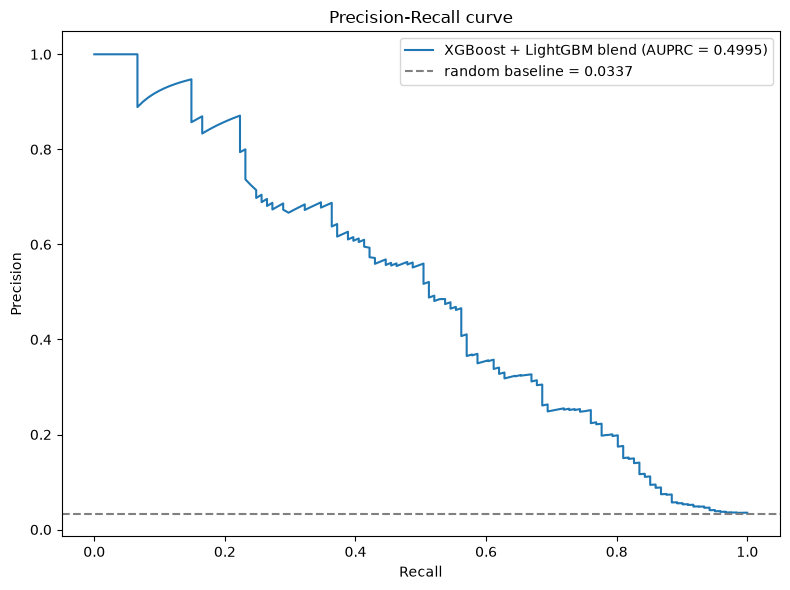

              precision    recall  f1-score   support

           0     0.9828    0.9862    0.9845      3467
           1     0.5596    0.5041    0.5304       121

    accuracy                         0.9699      3588
   macro avg     0.7712    0.7451    0.7574      3588
weighted avg     0.9685    0.9699    0.9691      3588



,threshold,predicted_positive,precision,recall,f1
0,0.05,3455,0.0350,1.0000,0.0677
1,0.10,3300,0.0358,0.9752,0.0690
2,0.15,3138,0.0373,0.9669,0.0718
3,0.20,2954,0.0389,0.9504,0.0748
4,0.25,2773,0.0411,0.9421,0.0788
5,0.30,2582,0.0442,0.9421,0.0844
6,0.35,2353,0.0480,0.9339,0.0914
7,0.40,2155,0.0515,0.9174,0.0975
8,0.45,1975,0.0552,0.9008,0.1040
9,0.50,1757,0.0609,0.8843,0.1140


In [106]:
val_probabilities = nlp.blend_rank_scores(
    xgb_model.predict_rank_score(X_val), lgbm_model.predict_rank_score(X_val))
tuned_threshold = best_threshold_by_f1(y_val, val_probabilities)
display(metrics_table({
    "validation @ 0.50": evaluate_predictions(y_val, val_probabilities, 0.5),
    "validation @ tuned": evaluate_predictions(y_val, val_probabilities, tuned_threshold),
}))
fig, ax = plt.subplots(figsize=(8, 6))
plot_precision_recall(y_val, val_probabilities, label="XGBoost + LightGBM blend", ax=ax)
plt.tight_layout(); plt.show()
print(classification_report(
    y_val, (val_probabilities >= tuned_threshold).astype(int), digits=4))
display(threshold_sweep(y_val, val_probabilities))

In [107]:
display(nlp.feature_importance_table(xgb_model.models_[0], final_features)
        .head(15).rename(columns={"importance": "xgboost_importance"}))

,feature,xgboost_importance
0,dporpag_latest,0.072009
1,dporpag_mean,0.055787
2,gbpm_mean,0.039516
3,dporpag_max,0.032617
4,Rec Rank_max,0.016824
5,Rec Rank_latest,0.016033
6,gbpm_latest,0.014229
7,Rec Rank_mean,0.014110
8,bpm_mean,0.013439
9,porpag_mean,0.012485


In [108]:
model_performance_explanations = """
Two evaluations are reported and they disagree, which is the substantive finding of this experiment.

The era-shifted holdout is the selection criterion. Fitting on players who finished college before a cutoff and scoring those who finished after reproduces the structure of the real task. Under it, within-season standardisation beats the raw representation at every cutoff tested, and the algorithm blend beats XGBoost alone at every cutoff by roughly 0.006. Same-era random folds disagree about the standardisation, scoring it lower than the raw features it replaces. That disagreement is expected and is the point: random folds contain no era shift, so they cannot measure resistance to one, and judging an era-robustness technique on them is using the wrong instrument.

The gap between the two evaluations, roughly 0.06 AUPRC, is also the honest correction to apply to every cross-validated figure reported in Experiments 1 and 2. Those numbers describe same-era ranking and overstate what transfers.

The leaderboard has since confirmed the direction of both changes, and calibrating against it is instructive. The era-shifted estimate predicted the blend would add roughly 0.006; the measured Kaggle improvement was 0.015, from 0.57474 to 0.58982. An earlier prediction from the same instrument slightly overstated a gain. Era-shifted validation is therefore reliable about the *direction* of a change but noisy about its magnitude, which is a more honest characterisation than treating it as a forecast.

One superseded result belongs here. An earlier version of this experiment ensembled two *representations*, a raw view and a standardised view, through a single algorithm. Once LightGBM is present that second view becomes redundant: reintroducing it changed nothing measurable. Algorithm diversity and representation diversity act as substitutes on this problem rather than complements, so the simpler configuration is kept.

Feature importance is reported as a diagnostic only, since gain importance is computed on training data and is biased towards high-cardinality continuous features. Notably several Rec Rank aggregates rank highly, and those are exactly the columns an earlier 30% missingness filter had discarded, which is direct evidence that the filter was removing signal.
"""

In [109]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view

In [110]:
# The threshold sweep is a technical artefact until expressed as scouting
# workload: given capacity to evaluate N players in depth, how many genuine
# future NBA players does that shortlist contain?
rows = []
total_positives = int(y_val.sum())
for size in (10, 25, 50, 100, 200):
    if size > len(y_val):
        continue
    cutoff = np.sort(val_probabilities)[-size]
    picked = val_probabilities >= cutoff
    found = int(y_val[picked].sum())
    rows.append({"shortlist_size": size,
                 "genuine_prospects_found": found,
                 "precision_%": round(found / picked.sum() * 100, 1),
                 "recall_%": round(found / total_positives * 100, 1),
                 "lift_vs_random": round((found / picked.sum()) / y_val.mean(), 1)})
print(f"Validation pool: {len(y_val)} players, {total_positives} reached a "
      f"sustained NBA career ({y_val.mean():.2%}).")
display(pd.DataFrame(rows))

Validation pool: 3588 players, 121 reached a sustained NBA career (3.37%).


,shortlist_size,genuine_prospects_found,precision_%,recall_%,lift_vs_random
0,10,9,90.0,7.4,26.7
1,25,21,84.0,17.4,24.9
2,50,34,68.0,28.1,20.2
3,100,56,56.0,46.3,16.6
4,200,71,35.5,58.7,10.5


In [111]:
business_impacts_explanations = """
The model's value is prioritisation rather than classification. The shortlist table expresses the threshold choice as the question a scouting department actually faces: given capacity to evaluate a fixed number of players in depth, how many genuine future NBA players does that shortlist contain, and how many are missed?

The lift column is the operationally meaningful figure, since it states how much better the shortlist is than drawing the same number of players at random from the same pool. At small shortlist sizes precision is many times the 3.4% base rate, which is precisely the regime a scouting department operates in, because evaluation capacity is always far smaller than the candidate pool.

Several limitations bound any practical use. Because the positive class is rare, recall at a workable shortlist size is inevitably limited: the model narrows a search, it does not close it, and false negatives are players with genuine NBA futures who never receive the attention that might have confirmed them. The threshold must be chosen from the organisation's own costs and capacity rather than from validation F1, which is reported only as a diagnostic.

The era analysis carries a direct operational warning: performance degrades measurably when the model is applied to a cohort several years later than its training data, so it must be refitted as new seasons become available rather than deployed once and trusted indefinitely. Subgroup performance by conference and playing position should be audited before deployment, because players from smaller programmes carry systematically more missing statistics and are therefore described less reliably by the model.

Finally, the ensemble is harder to interpret than a single model, which matters when a scout asks why a particular player was ranked where he was. The feature importances reported above describe one member rather than the blend, and should not be presented to stakeholders as an explanation of the final ranking.
"""

In [112]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

---
## H. Project Outcomes

In [113]:
experiment_outcome = "Hypothesis Confirmed"

In [114]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [115]:
experiment_results_explanations = """
Both hypotheses were confirmed, and the leaderboard has since corroborated both.

The validation hypothesis held in the specific form predicted in advance. Adversarial validation separates the 2008-2016 and 2020-2023 feature distributions at roughly 0.94 AUC, confirming the shift is severe rather than incidental. Within-season standardisation, which scores worse than raw features on random folds and had been rejected on that basis earlier in this project, wins under era-shifted validation at every cutoff tested. That reversal was predicted before it was measured, from the argument that random folds cannot detect resistance to a shift they do not contain. Removing jersey number, the strongest era marker in the feature set and a variable with no causal link to the outcome, contributed a further small consistent gain.

The modelling hypothesis held under the strict test set for it. Blending XGBoost with LightGBM improved era-shifted AUPRC by roughly 0.006 and won at every cutoff, the same standard under which eighteen hyperparameter candidates were rejected. On the leaderboard the blend scored 0.58982 against 0.57474 for the previous configuration, a gain of 0.015. Worth noting for calibration: the era-shifted estimate understated that gain by more than a factor of two, while an earlier estimate from the same instrument had slightly overstated one. It is a reliable guide to direction and an unreliable one to magnitude.

An unusually long list of negative results bounds what remains available, and all are recorded rather than discarded. Restoring the three interaction features from the original notebook did not help. Explicit missingness indicators did not help. Minutes-weighted career means did not help. CatBoost as a third ensemble member was clearly worse than either other family. Reducing the feature set to its most important 20, 40, 80 or 120 columns hurt at every size, and restricting training to more recent cohorts hurt substantially. The last two are notable because both are standard responses to covariate shift and neither worked here. Ensembling a second data representation was superseded once a second algorithm was present.

The reasonable conclusion is that this feature set is close to exhausted. Every axis tried, features, feature count, training window, model family, ensembling and hyperparameters, produced either nothing or a gain well under 0.02. Meaningful further improvement most likely requires information the dataset does not contain, such as per-game logs, strength-of-schedule adjustment, injury history or physical testing data, rather than further transformation of the columns already present.
"""

In [116]:
# Do not modify this code
print_tile(size="h3", key='experiment_results_explanations', value=experiment_results_explanations)

---
## Kaggle Submission

The model predicts one score per player, so no aggregation step is needed here. That is the point of the player-level design: the unit the model was fitted on is the unit the competition scores.

In [117]:
# Refit both families on every labelled player, then blend their rank scores.
final_xgb = SeedBaggedXGB(seeds=BAGGING_SEEDS).fit(X_all, y_all)
final_lgbm = nlp.SeedBaggedLGBM(seeds=BAGGING_SEEDS).fit(X_all, y_all)

kaggle_scores = nlp.blend_rank_scores(
    final_xgb.predict_rank_score(X_kaggle),
    final_lgbm.predict_rank_score(X_kaggle),
)
submission = build_submission(test_pids, kaggle_scores, as_ranks=True)

save_model({"xgboost": final_xgb, "lightgbm": final_lgbm, "weights": (0.5, 0.5)},
           REPO / "models" /
           "36120-26SP-group38-25740655-experiment-3-xgb-lgbm.joblib")
print("Players predicted:", len(submission))
print("Prediction range:", round(submission["label"].min(), 6),
      "to", round(submission["label"].max(), 6))
display(submission.head())

Players predicted: 6261
Prediction range: 8e-05 to 0.99992


,pid,label
0,27085,0.189187
1,30747,0.783820
2,32932,0.546957
3,33635,0.908561
4,33955,0.953921


In [118]:
# Validates columns, row count, id uniqueness, missing values, the [0, 1] range,
# and that the id set matches the competition's sample submission exactly.
submission_dir = (Path("/content/drive/MyDrive/AML_AT1")
                  if Path("/content/drive").exists()
                  else REPO / "data" / "processed")
submission_path = save_submission(
    submission,
    submission_dir / "36120-26SP-group38-25740655-experiment-3-submission.csv",
    sample_submission=sample_submission,
)
print("Submission passed all validation checks.")
print("Saved to:", submission_path.resolve())

Submission passed all validation checks.
Saved to: /Users/shreeyapatil/Downloads/NEW ASSIGNMENTB 1/FINAL/36120-26SP-group38-experiments/data/processed/36120-26SP-group38-25740655-experiment-3-submission.csv
